# CC3045 – Deep Learning · Laboratorio 10

In [1]:
import os, time, random
import numpy as np
import torch
import torch.nn.functional as F
import torchvision
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights
from PIL import Image
import matplotlib
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
os.makedirs("figs", exist_ok=True)
print("torch", torch.__version__, "| torchvision", torchvision.__version__)

torch 2.13.0+cpu | torchvision 0.28.0+cpu


## Task 1 – Grad-CAM y CAM sobre ResNet-18
### Task 1.1 – Modelo, preprocesamiento y predicciones

In [2]:
# ResNet-18 con pesos preentrenados de ImageNet, en modo evaluación.
weights = ResNet18_Weights.IMAGENET1K_V1
model = resnet18(weights=weights).eval()
CATEGORIAS = weights.meta["categories"]

MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
# Redimensión a 256 en el lado corto -> recorte central 224x224 (imagen "visible", en [0,1])
recorte = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor()])
# Normalización por canal: x_norm = (x - mu_c) / sigma_c
normalizar = transforms.Normalize(MEAN, STD)

IMAGENES = {
    "a": {"ruta": "imagenes/img_a.jpg", "desc": "objeto claro y centrado", "fuente": "https://pampermut.com/blog/wp-content/uploads/2025/02/Plantilla-Blog-1733-x-1155-px-13.jpg"},
    "b": {"ruta": "imagenes/img_b.jpg", "desc": "dos objetos de clases distintas", "fuente": "https://images.imagerenderer.com/images-medium-large-5/2-bernese-mountain-puppy-and-kitten-jean-michel-labat.jpg"},
    "c": {"ruta": "imagenes/img_c.jpg", "desc": "objeto sobre un fondo engañoso", "fuente": "https://media.istockphoto.com/id/482729398/photo/cow-on-the-beach.jpg?s=612x612&w=0&k=20&c=HDxa-_7Y2lFnYLV7AE-za9KXyupNkqh7y1EO7PvTpMk="},
}

def cargar(ruta):
    """Devuelve (imagen 224x224 en [0,1] como tensor 3xHxW, entrada normalizada 1x3x224x224)."""
    img = recorte(Image.open(ruta).convert("RGB"))
    return img, normalizar(img).unsqueeze(0)

datos_img = {k: cargar(v["ruta"]) for k, v in IMAGENES.items()}

@torch.no_grad()
def top5(x):
    p = F.softmax(model(x), dim=1)[0]   # softmax sobre los logits y^c
    pr, idx = p.topk(5)
    return [(int(i), CATEGORIAS[i], float(q)) for q, i in zip(pr, idx)]

TOP5 = {}
for k, (img, x) in datos_img.items():
    TOP5[k] = top5(x)
    print(f"Imagen ({k}) – {IMAGENES[k]['desc']} – fuente: {IMAGENES[k]['fuente']}")
    for i, nombre, q in TOP5[k]:
        print(f"   {i:4d}  {nombre:30s} p = {q:.4f}")

Imagen (a) – objeto claro y centrado – fuente: https://pampermut.com/blog/wp-content/uploads/2025/02/Plantilla-Blog-1733-x-1155-px-13.jpg
    239  Bernese mountain dog           p = 0.9893
    240  Appenzeller                    p = 0.0071
    238  Greater Swiss Mountain dog     p = 0.0014
    241  EntleBucher                    p = 0.0010
    214  Gordon setter                  p = 0.0005
Imagen (b) – dos objetos de clases distintas – fuente: https://images.imagerenderer.com/images-medium-large-5/2-bernese-mountain-puppy-and-kitten-jean-michel-labat.jpg
    239  Bernese mountain dog           p = 0.9314
    240  Appenzeller                    p = 0.0212
    232  Border collie                  p = 0.0104
    264  Cardigan                       p = 0.0102
    238  Greater Swiss Mountain dog     p = 0.0042
Imagen (c) – objeto sobre un fondo engañoso – fuente: https://media.istockphoto.com/id/482729398/photo/cow-on-the-beach.jpg?s=612x612&w=0&k=20&c=HDxa-_7Y2lFnYLV7AE-za9KXyupNkqh7y1EO7Pv

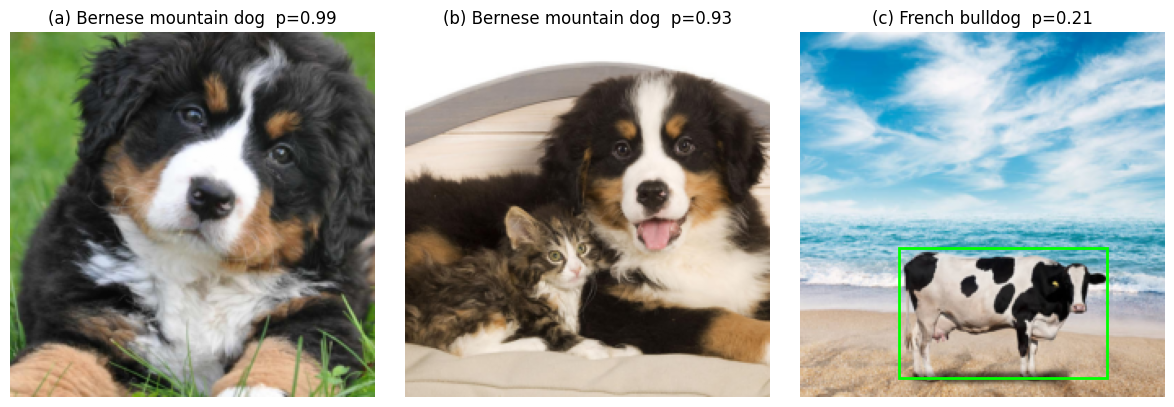

Recuadro de (c) en 224x224: (60, 132, 188, 212)


In [ ]:
# Clase del segundo objeto de la imagen (b) (índice de ImageNet) y recuadro del objeto en (c),
# en coordenadas de la imagen 224x224: (x0, y0, x1, y1), con x hacia la derecha e y hacia abajo.
CLASE_B2 = 281     # "tabby" (gato atigrado), el gatito de la imagen (b)
BBOX_C = (60, 132, 188, 212)   # vaca en la playa, medido sobre el recorte 224x224
assert CLASE_B2 is not None and BBOX_C is not None, "Defina CLASE_B2 y BBOX_C"

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, (k, (img, _)) in zip(ax, datos_img.items()):
    a.imshow(img.permute(1, 2, 0)); a.set_title(f"({k}) {TOP5[k][0][1]}  p={TOP5[k][0][2]:.2f}"); a.axis("off")
x0, y0, x1, y1 = BBOX_C
ax[2].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="lime", lw=2))
plt.tight_layout(); plt.savefig("figs/t1_imagenes.png", dpi=150); plt.show()
print("Recuadro de (c) en 224x224:", BBOX_C)

### Task 1.2 – Grad-CAM desde cero
Para la clase $c$ y la última capa convolucional (`layer4`, $A\in\mathbb{R}^{512\times7\times7}$):
$$\alpha_k^c=\frac{1}{Z}\sum_{i,j}\frac{\partial y^c}{\partial A_{ij}^k},\qquad L^c=\mathrm{ReLU}\Big(\sum_k\alpha_k^c A^k\Big),\qquad Z=49.$$
Se retropropaga desde el **logit** $y^c$ (antes del softmax).

C:\Users\isabe\AppData\Local\Temp\ipykernel_9096\1328613121.py:19: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:823.)
  return {"alpha": alpha, "A": A, "lin": lin, "mapa": up, "logit": float(logits[0, c])}


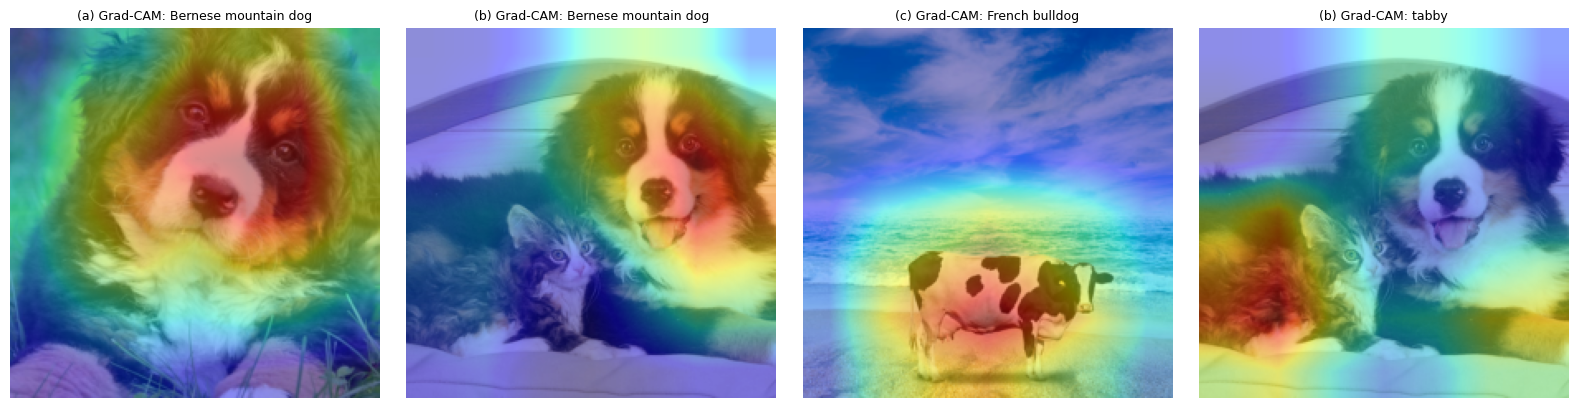

In [ ]:
class GradCAM:
    def __init__(self, model, capa):
        self.model, self.A, self.dA = model, None, None
        # hook de avance. Guarda las activaciones A (1x512x7x7)
        capa.register_forward_hook(lambda m, i, o: setattr(self, "A", o.detach()))
        # hook de retroceso. Guarda dy^c/dA (gradiente respecto a la salida de la capa)
        capa.register_full_backward_hook(lambda m, gi, go: setattr(self, "dA", go[0].detach()))

    def __call__(self, x, c):
        self.model.zero_grad()
        logits = self.model(x)
        logits[0, c].backward()
        A, dA = self.A[0], self.dA[0]
        alpha = dA.mean(dim=(1, 2))
        lin = (alpha[:, None, None] * A).sum(0)
        cam = F.relu(lin)
        up = F.interpolate(cam[None, None], size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
        up = (up - up.min()) / (up.max() - up.min() + 1e-12)
        return {"alpha": alpha, "A": A, "lin": lin, "mapa": up, "logit": float(logits[0, c])}

gradcam = GradCAM(model, model.layer4)

def superponer(ax, img, mapa, titulo):
    ax.imshow(img.permute(1, 2, 0)); ax.imshow(mapa, cmap="jet", alpha=0.45); ax.set_title(titulo, fontsize=9); ax.axis("off")

GC = {}   # resultados de Grad-CAM para la clase top-1 de cada imagen
for k, (img, x) in datos_img.items():
    GC[k] = gradcam(x, TOP5[k][0][0])
GC_B2 = gradcam(datos_img["b"][1], CLASE_B2)

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, k in zip(ax, "abc"):
    superponer(a, datos_img[k][0], GC[k]["mapa"], f"({k}) Grad-CAM: {TOP5[k][0][1]}")
superponer(ax[3], datos_img["b"][0], GC_B2["mapa"], f"(b) Grad-CAM: {CATEGORIAS[CLASE_B2]}")
plt.tight_layout(); plt.savefig("figs/t1_gradcam.png", dpi=150); plt.show()

### Task 1.3 – CAM desde los pesos de `fc` y relación con Grad-CAM
Como $y^c=\sum_k w_k^c\,\frac{1}{Z}\sum_{ij}A^k_{ij}+b^c$, se define $M^c_{ij}=\sum_k w^c_k A^k_{ij}$ y debe cumplirse
$\frac{1}{Z}\sum_{ij}M^c_{ij}+b^c=y^c$. Además $\partial y^c/\partial A^k_{ij}=w^c_k/Z$ en toda posición, así que $\alpha^c_k=w^c_k/Z$
y $Z\cdot\sum_k\alpha^c_kA^k=M^c$.

In [ ]:
W, b = model.fc.weight.detach(), model.fc.bias.detach() 
Z = 49

def minmax(m): return (m - m.min()) / (m.max() - m.min() + 1e-12)

def cam_desde_fc(A, c):
    return (W[c][:, None, None] * A).sum(0)          # M^c_ij = sum_k w_k^c A^k_ij (sin gradientes)

T13 = {}
for k in "abc":
    c, r = TOP5[k][0][0], GC[k]
    M = cam_desde_fc(r["A"], c)
    y_rec = float(M.sum() / Z + b[c])
    err_logit = abs(y_rec - r["logit"])
    err_gc = float((Z * r["lin"] - M).abs().max())    # max |Z L^c_lin - M^c| en las 49 posiciones
    err_norm = float((minmax(F.relu(r["lin"])) - minmax(F.relu(M))).abs().max())
    T13[k] = dict(logit=r["logit"], y_rec=y_rec, err_logit=err_logit, err_gc=err_gc, err_norm=err_norm)
    print(f"({k}) y^c = {r['logit']:.6f} | (1/Z)ΣM + b = {y_rec:.6f} | |err| = {err_logit:.2e} | "
          f"max|Z·L_lin − M| = {err_gc:.2e} | max|norm(ReLU L) − norm(ReLU M)| = {err_norm:.2e}")

(a) y^c = 18.133539 | (1/Z)ΣM + b = 18.133541 | |err| = 1.91e-06 | max|Z·L_lin − M| = 5.72e-06 | max|norm(ReLU L) − norm(ReLU M)| = 1.79e-07
(b) y^c = 13.027204 | (1/Z)ΣM + b = 13.027205 | |err| = 9.54e-07 | max|Z·L_lin − M| = 3.81e-06 | max|norm(ReLU L) − norm(ReLU M)| = 1.79e-07
(c) y^c = 11.024663 | (1/Z)ΣM + b = 11.024664 | |err| = 9.54e-07 | max|Z·L_lin − M| = 3.81e-06 | max|norm(ReLU L) − norm(ReLU M)| = 2.38e-07


### Task 1.4 – Análisis
**(a)** $\alpha_k^c$ contra $w_k^c/Z$ en los cinco canales de mayor peso (imagen a).

In [6]:
c_a = TOP5["a"][0][0]
alpha_a = GC["a"]["alpha"]
canales = W[c_a].topk(5).indices
print(f"Clase de (a): {CATEGORIAS[c_a]}")
print(" canal      alpha_k^c        w_k^c / Z      error relativo")
T14a = []
for kk in canales.tolist():
    al, wz = float(alpha_a[kk]), float(W[c_a, kk] / Z)
    rel = abs(al - wz) / abs(wz)
    T14a.append((kk, al, wz, rel))
    print(f"{kk:6d}  {al: .10f}  {wz: .10f}  {rel:.2e}")
print("Error relativo máximo sobre los 512 canales:",
      f"{float(((alpha_a - W[c_a] / Z).abs() / (W[c_a] / Z).abs().clamp_min(1e-12)).max()):.2e}")
print("Épsilon de máquina float32:", torch.finfo(torch.float32).eps)

Clase de (a): Bernese mountain dog
 canal      alpha_k^c        w_k^c / Z      error relativo
   266   0.0075867060   0.0075867055  6.14e-08
   274   0.0067644869   0.0067644869  0.00e+00
   414   0.0062553408   0.0062553412  7.44e-08
   402   0.0055082487   0.0055082482  8.45e-08
   242   0.0051864982   0.0051864982  0.00e+00
Error relativo máximo sobre los 512 canales: 2.33e-07
Épsilon de máquina float32: 1.1920928955078125e-07


**(b)** IoU entre el 20 % de píxeles de mayor valor en los mapas de las dos clases de la imagen (b).

(b) clases: Bernese mountain dog vs tabby  ->  IoU(top 20%) = 0.0000
Correlación de Pearson entre ambos mapas 7x7: -0.0941


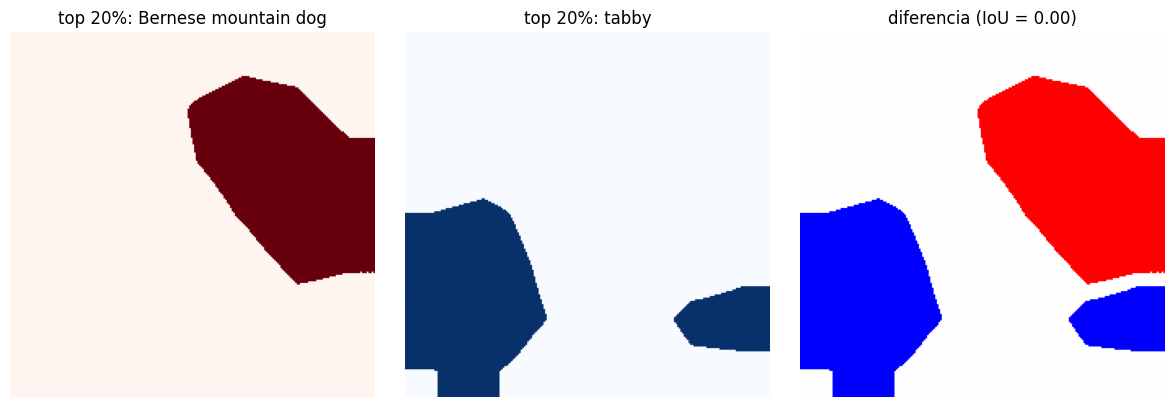

In [7]:
def top_frac(mapa, frac=0.20):
    umbral = torch.quantile(mapa.flatten(), 1 - frac)
    return mapa >= umbral

m1, m2 = top_frac(GC["b"]["mapa"]), top_frac(GC_B2["mapa"])
iou_b = float((m1 & m2).sum() / (m1 | m2).sum())
print(f"(b) clases: {TOP5['b'][0][1]} vs {CATEGORIAS[CLASE_B2]}  ->  IoU(top 20%) = {iou_b:.4f}")
print("Correlación de Pearson entre ambos mapas 7x7:",
      f"{float(np.corrcoef(GC['b']['lin'].flatten(), GC_B2['lin'].flatten())[0, 1]):.4f}")

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(m1, cmap="Reds"); ax[0].set_title(f"top 20%: {TOP5['b'][0][1]}")
ax[1].imshow(m2, cmap="Blues"); ax[1].set_title(f"top 20%: {CATEGORIAS[CLASE_B2]}")
ax[2].imshow(m1.float() - m2.float(), cmap="bwr"); ax[2].set_title(f"diferencia (IoU = {iou_b:.2f})")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig("figs/t1_iou_b.png", dpi=150); plt.show()

**(c)** Masa del mapa dentro del recuadro y prueba causal (fondo reemplazado por gris medio, 0.5 en píxeles).

(c) clase French bulldog: masa del mapa dentro del recuadro = 0.4634 (área del recuadro = 0.2041)
    p(original) = 0.2064 | p(fondo gris) = 0.0280 | cambio = -0.1785
    top-3 con fondo gris: [('German short-haired pointer', 0.0859895795583725), ('bluetick', 0.0840713232755661), ('Great Dane', 0.08242271840572357)]


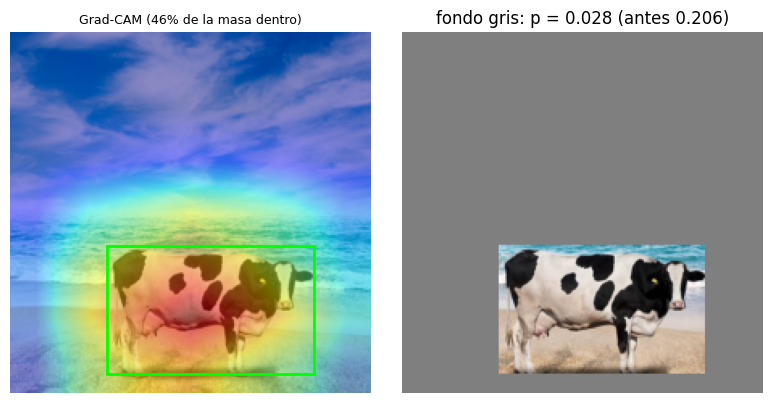

In [ ]:
c_c = TOP5["c"][0][0]
x0, y0, x1, y1 = BBOX_C
mapa_c = GC["c"]["mapa"]
dentro = torch.zeros(224, 224, dtype=torch.bool); dentro[y0:y1, x0:x1] = True
masa_dentro = float(mapa_c[dentro].sum() / mapa_c.sum())
frac_area = float(dentro.float().mean())

img_c = datos_img["c"][0].clone()
img_gris = img_c.clone(); img_gris[:, ~dentro] = 0.5
with torch.no_grad():
    p_orig = float(F.softmax(model(normalizar(img_c)[None]), 1)[0, c_c])
    p_gris_all = F.softmax(model(normalizar(img_gris)[None]), 1)[0]
p_gris = float(p_gris_all[c_c])
top_gris = [(CATEGORIAS[i], float(p_gris_all[i])) for i in p_gris_all.topk(3).indices]
print(f"(c) clase {CATEGORIAS[c_c]}: masa del mapa dentro del recuadro = {masa_dentro:.4f} (área del recuadro = {frac_area:.4f})")
print(f"    p(original) = {p_orig:.4f} | p(fondo gris) = {p_gris:.4f} | cambio = {p_gris - p_orig:+.4f}")
print("    top-3 con fondo gris:", top_gris)

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
superponer(ax[0], img_c, mapa_c, f"Grad-CAM ({masa_dentro:.0%} de la masa dentro)")
ax[0].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="lime", lw=2))
ax[1].imshow(img_gris.permute(1, 2, 0)); ax[1].set_title(f"fondo gris: p = {p_gris:.3f} (antes {p_orig:.3f})"); ax[1].axis("off")
plt.tight_layout(); plt.savefig("figs/t1_causal_c.png", dpi=150); plt.show()

## Task 2 – SHAP sobre German Credit
### Task 2.1 – Datos y modelo

In [ ]:
import itertools, math, warnings
import pandas as pd
import shap
from scipy.stats import spearmanr
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.inspection import permutation_importance
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print("shap", shap.__version__)

SEED = 42
np.random.seed(SEED)
datos = fetch_openml("credit-g", version=1, as_frame=True)
X_raw = datos.data.copy()
y = (datos.target == "good").astype(int).rename("good")      # good -> 1, bad -> 0

NUM = list(X_raw.select_dtypes(include="number").columns)
CAT = [c for c in X_raw.columns if c not in NUM]
print(f"{X_raw.shape[0]} solicitudes, {len(NUM)} numéricas, {len(CAT)} categóricas")

# Codificador ordinal: los códigos 0,1,2,... son ARBITRARIOS (orden alfabético de categorías) pero el modelo
# los trata como numéricos.
enc = OrdinalEncoder()
X = X_raw.copy()
X[CAT] = enc.fit_transform(X_raw[CAT].astype(str))
X = X.astype(float)
COLS = list(X.columns)

def decodificar(col, valor):
    """Código ordinal -> categoría original (para tablas y gráficos)."""
    if col in CAT:
        return enc.categories_[CAT.index(col)][int(round(valor))]
    return valor

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)

def entrenar(Xtr, ytr):
    return GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=SEED).fit(Xtr, ytr)

gb = entrenar(X_tr, y_tr)
p_te = gb.predict_proba(X_te)[:, 1]
print(f"Exactitud (prueba) = {accuracy_score(y_te, p_te >= 0.5):.4f} | AUC (prueba) = {roc_auc_score(y_te, p_te):.4f}")

shap 0.51.0
1000 solicitudes, 7 numéricas, 13 categóricas


Exactitud (prueba) = 0.7750 | AUC (prueba) = 0.7650


### Task 2.2 – TreeSHAP intervencional en log-odds
Salida explicada: $f(x)=\log\frac{p}{1-p}$ (`decision_function`). Eficiencia: $\phi_0+\sum_j\phi_j(x)=f(x)$.

In [ ]:
fondo = X_tr.sample(100, random_state=SEED) # fondo de 100 instancias de entrenamiento al azar
expl = shap.TreeExplainer(gb, data=fondo, feature_perturbation="interventional", model_output="raw")
sv = expl(X_te)
phi, phi0 = sv.values, float(np.atleast_1d(sv.base_values)[0])
f_te = gb.decision_function(X_te)

# eficiencia
err_ef = np.abs(phi0 + phi.sum(1) - f_te).max()
print(f"(a) max |phi0 + Σ phi_j − f(x)| = {err_ef:.3e}")
# valor base = E_fondo[f(x)]
print(f"(b) phi0 = {phi0:.6f} | promedio de f sobre el fondo = {gb.decision_function(fondo).mean():.6f}")

# importancia global I_j = (1/N) Σ_n |phi_j^(n)| y permutación (AUC, 10 repeticiones)
I = pd.Series(np.abs(phi).mean(0), index=COLS).sort_values(ascending=False)
perm = permutation_importance(gb, X_te, y_te, scoring="roc_auc", n_repeats=10, random_state=SEED)
P = pd.Series(perm.importances_mean, index=COLS).sort_values(ascending=False)
rho_IP = spearmanr(I[COLS], P[COLS]).statistic
print("\nTop 5 SHAP (I_j):"); print(I.head(5).round(4).to_string())
print("\nTop 5 permutación (caída media de AUC):"); print(P.head(5).round(4).to_string())
print(f"\nSpearman entre los rankings completos (20 variables) = {rho_IP:.4f}")
rank_tab = pd.DataFrame({"I_j": I, "rank_SHAP": I.rank(ascending=False).astype(int),
                         "perm": P, "rank_perm": P.rank(ascending=False).astype(int)}).sort_values("rank_SHAP")
rank_tab

(a) max |phi0 + Σ phi_j − f(x)| = 9.587e-08
(b) phi0 = 1.334498 | promedio de f sobre el fondo = 1.334498



Top 5 SHAP (I_j):
checking_status    0.7355
credit_amount      0.4871
purpose            0.4843
duration           0.3780
savings_status     0.3397

Top 5 permutación (caída media de AUC):
checking_status    0.1190
credit_amount      0.0764
duration           0.0579
credit_history     0.0396
savings_status     0.0262

Spearman entre los rankings completos (20 variables) = 0.7023


,I_j,rank_SHAP,perm,rank_perm
checking_status,0.735485,1,0.119000,1
credit_amount,0.487090,2,0.076405,2
purpose,0.484277,3,0.003750,12
duration,0.378035,4,0.057905,3
savings_status,0.339725,5,0.026155,5
age,0.292273,6,-0.005417,20
credit_history,0.233932,7,0.039643,4
installment_commitment,0.209947,8,0.010083,7
residence_since,0.197691,9,0.002202,13
other_payment_plans,0.181824,10,0.020119,6


Cliente aprobado: índice 175, p(good) = 0.9994
Cliente rechazado: índice 721, p(good) = 0.0517
Tres mayores contribuciones del cliente aprobado: [('purpose', 'used car', 1.5459), ('age', 53.0, 1.0879), ('residence_since', 1.0, 1.0134)]


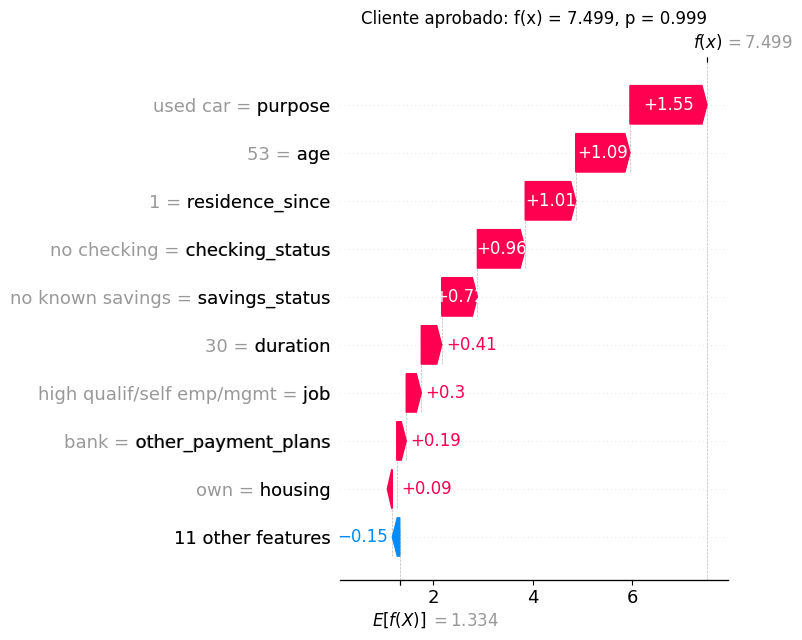

Tres mayores contribuciones del cliente rechazado: [('credit_history', 'all paid', -1.2592), ('savings_status', '>=1000', 1.0271), ('credit_amount', 433.0, -0.9924)]


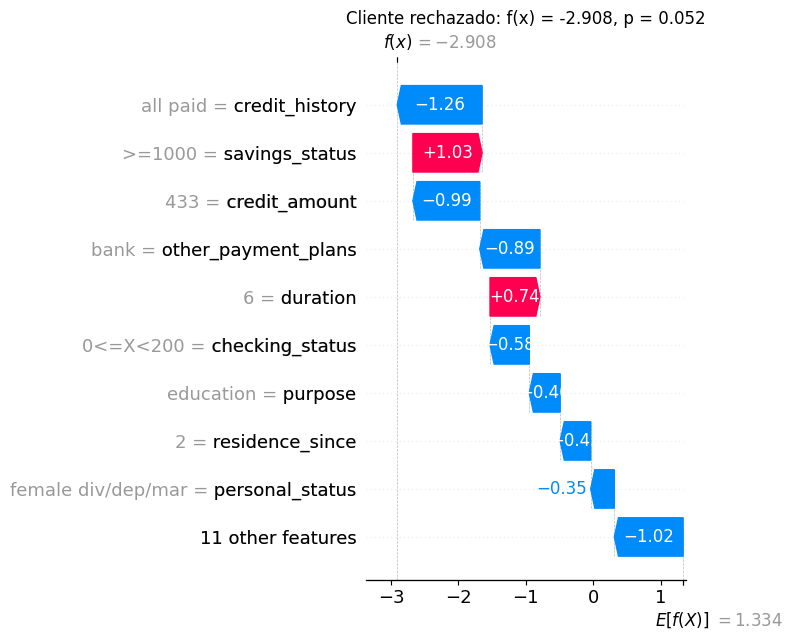

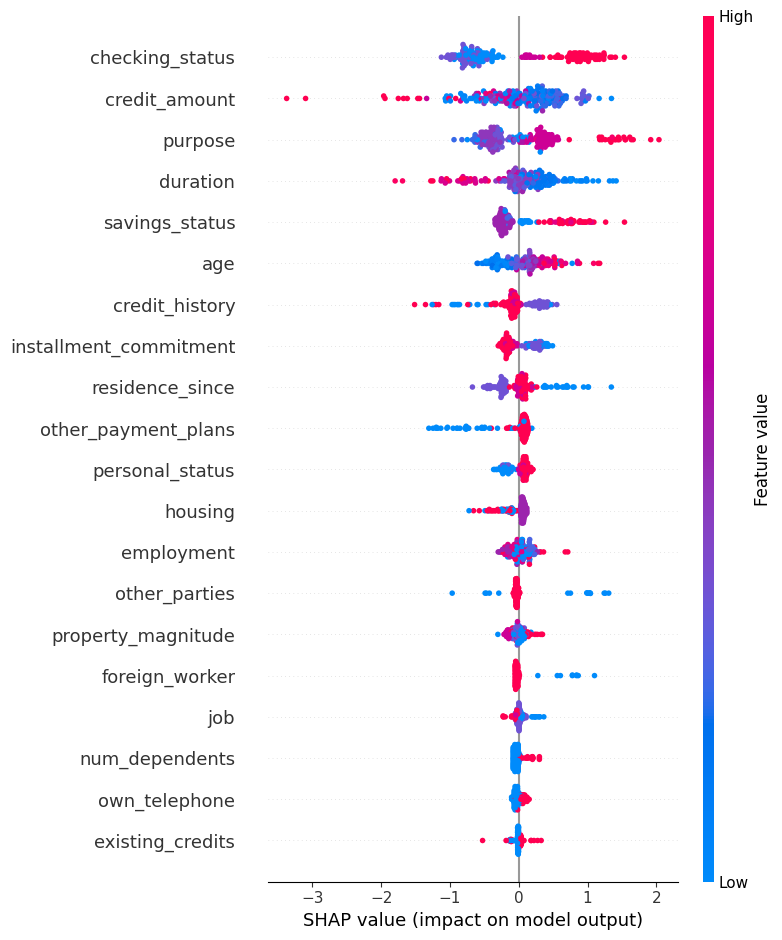

In [ ]:
# Un cliente aprobado (p>0.8) y uno rechazado (p<0.2). Se toman el de mayor y el de menor probabilidad.
i_ok = int(np.argmax(p_te)); i_rech = int(np.argmin(p_te))
print(f"Cliente aprobado: índice {X_te.index[i_ok]}, p(good) = {p_te[i_ok]:.4f}")
print(f"Cliente rechazado: índice {X_te.index[i_rech]}, p(good) = {p_te[i_rech]:.4f}")

X_te_dec = X_te.copy().astype(object)
for c in CAT:
    X_te_dec[c] = [decodificar(c, v) for v in X_te[c]]
sv_dec = shap.Explanation(values=phi, base_values=np.full(len(X_te), phi0), data=X_te_dec.values, feature_names=COLS)

def top3(i):
    o = np.argsort(-np.abs(phi[i]))[:3]
    return [(COLS[j], X_te_dec.iloc[i, j], round(float(phi[i, j]), 4)) for j in o]

for nombre, i in [("aprobado", i_ok), ("rechazado", i_rech)]:
    print(f"Tres mayores contribuciones del cliente {nombre}:", top3(i))
    plt.figure(); shap.plots.waterfall(sv_dec[i], max_display=10, show=False)
    plt.title(f"Cliente {nombre}: f(x) = {f_te[i]:.3f}, p = {p_te[i]:.3f}"); plt.tight_layout()
    plt.savefig(f"figs/t2_waterfall_{nombre}.png", dpi=150, bbox_inches="tight"); plt.show()

plt.figure(); shap.plots.beeswarm(sv, max_display=20, show=False); plt.tight_layout()
plt.savefig("figs/t2_beeswarm.png", dpi=150, bbox_inches="tight"); plt.show()

### Task 2.3 – Variable redundante
$x_{dup}=x+0.05\,\sigma_x\,\epsilon$, $\epsilon\sim\mathcal N(0,1)$. Se comparan TreeSHAP intervencional (con fondo) y `tree_path_dependent` (sin fondo).

In [ ]:
v_top = next(c for c in I.index if c in NUM) # variable numérica de mayor I_j
rng = np.random.default_rng(SEED)
X_dup = X.copy()
X_dup[v_top + "_copia"] = X[v_top] + 0.05 * X[v_top].std() * rng.standard_normal(len(X))
Xd_tr, Xd_te = X_dup.loc[X_tr.index], X_dup.loc[X_te.index]
gb_dup = entrenar(Xd_tr, y_tr)
print(f"Variable duplicada: {v_top} | AUC del modelo con 21 variables = {roc_auc_score(y_te, gb_dup.predict_proba(Xd_te)[:, 1]):.4f}")

j_o, j_c = COLS.index(v_top), Xd_te.shape[1] - 1
filas = {}
for nombre, ex in [("intervencional (fondo 100)",
                    shap.TreeExplainer(gb_dup, data=X_dup.loc[fondo.index], feature_perturbation="interventional")),
                   ("tree_path_dependent (sin fondo)",
                    shap.TreeExplainer(gb_dup, feature_perturbation="tree_path_dependent"))]:
    s = ex.shap_values(Xd_te)
    filas[nombre] = {"mean|phi_orig|": np.abs(s[:, j_o]).mean(), "mean|phi_copia|": np.abs(s[:, j_c]).mean(),
                     "mean|phi_orig+phi_copia|": np.abs(s[:, j_o] + s[:, j_c]).mean(),
                     "corr(phi_orig, phi_copia)": np.corrcoef(s[:, j_o], s[:, j_c])[0, 1]}
T23 = pd.DataFrame(filas).T
T23["I_j sin copia"] = I[v_top]
# cuántos cortes usa cada modelo sobre la variable original y la copia
usos = np.zeros(Xd_te.shape[1])
for est in gb_dup.estimators_[:, 0]:
    f_ = est.tree_.feature; usos += np.bincount(f_[f_ >= 0], minlength=Xd_te.shape[1])
print(f"Cortes del modelo con copia: {v_top} = {int(usos[j_o])}, copia = {int(usos[j_c])}")
T23.round(4)

Variable duplicada: credit_amount | AUC del modelo con 21 variables = 0.7671


Cortes del modelo con copia: credit_amount = 154, copia = 208


,mean|phi_orig|,mean|phi_copia|,mean|phi_orig+phi_copia|,"corr(phi_orig, phi_copia)",I_j sin copia
intervencional (fondo 100),0.5226,0.4219,0.5339,-0.3017,0.4871
tree_path_dependent (sin fondo),0.3812,0.3629,0.5303,-0.0758,0.4871


### Task 2.4 – KernelSHAP vs TreeSHAP
10 instancias de prueba, 2 000 muestras por instancia, fondos de 10, 50 y 100 (los primeros $k$ del fondo aleatorio del Task 2.2).
Se usa `l1_reg=False` para que KernelSHAP estime las 20 variables sin selección previa.

In [13]:
X10 = X_te.iloc[:10]
f_np = lambda Zm: gb.decision_function(pd.DataFrame(Zm, columns=COLS))
T24 = []
for k in [10, 50, 100]:
    fk = fondo.iloc[:k]
    t0 = time.perf_counter()
    ks = shap.KernelExplainer(f_np, fk.values).shap_values(X10.values, nsamples=2000, l1_reg=False, silent=True)
    t_kernel = time.perf_counter() - t0
    t0 = time.perf_counter()
    ts = shap.TreeExplainer(gb, data=fk, feature_perturbation="interventional").shap_values(X10)
    t_tree = time.perf_counter() - t0
    T24.append({"fondo": k, "MAE kernel vs tree": np.abs(ks - ts).mean(), "max |error|": np.abs(ks - ts).max(),
                "t KernelSHAP (s)": t_kernel, "t KernelSHAP por instancia (s)": t_kernel / 10, "t TreeSHAP (s)": t_tree,
                "evaluaciones por instancia": 2000 * k})
T24 = pd.DataFrame(T24).set_index("fondo")
T24.round(5)

,MAE kernel vs tree,max |error|,t KernelSHAP (s),t KernelSHAP por instancia (s),t TreeSHAP (s),evaluaciones por instancia
fondo,,,,,,
10,0.00227,0.01584,0.91348,0.09135,0.01608,20000
50,0.00395,0.02515,3.51157,0.35116,0.04023,100000
100,0.00377,0.02292,7.48782,0.74878,0.03283,200000


### Task 2.5 – Shapley exacto escrito a mano (6 variables numéricas)
$v(S)=\frac{1}{|B|}\sum_{b\in B} f(x_S, b_{\bar S})$ y
$\phi_i=\sum_{S\subseteq N\setminus\{i\}}\frac{|S|!\,(n-|S|-1)!}{n!}\,[v(S\cup\{i\})-v(S)]$, con $n=6$ y $2^6=64$ coaliciones.

In [ ]:
VARS6 = ["duration", "credit_amount", "installment_commitment", "residence_since", "age", "existing_credits"]
gb6 = entrenar(X_tr[VARS6], y_tr)
fondo50 = X_tr[VARS6].sample(50, random_state=SEED).values
n = len(VARS6)

def v_coaliciones(x):
    """v(S) para las 64 coaliciones, indexadas por máscara de bits (bit i = variable i en S)."""
    filas = []
    for mask in range(2 ** n):
        Zm = fondo50.copy()
        enS = [(mask >> i) & 1 == 1 for i in range(n)]
        Zm[:, enS] = x[enS] # variables de S fijas en la instancia, el resto del fondo
        filas.append(Zm)
    out = gb6.decision_function(pd.DataFrame(np.vstack(filas), columns=VARS6))
    return out.reshape(2 ** n, len(fondo50)).mean(1)

def shapley_exacto(x):
    v = v_coaliciones(x)
    phi_ = np.zeros(n)
    for i in range(n):
        for mask in range(2 ** n):
            if (mask >> i) & 1: continue
            s = bin(mask).count("1")
            peso = math.factorial(s) * math.factorial(n - s - 1) / math.factorial(n)
            phi_[i] += peso * (v[mask | (1 << i)] - v[mask])
    return phi_, v

X5 = X_te[VARS6].iloc[:5].values
tree6 = shap.TreeExplainer(gb6, data=pd.DataFrame(fondo50, columns=VARS6), feature_perturbation="interventional")
phi_tree6 = tree6.shap_values(pd.DataFrame(X5, columns=VARS6))
T25 = []
for r in range(5):
    ph, v = shapley_exacto(X5[r])
    T25.append({"instancia": X_te.index[r], "max|phi_exacto − phi_tree|": np.abs(ph - phi_tree6[r]).max(),
                "Σphi": ph.sum(), "v(N) − v(∅)": v[-1] - v[0], "|Σphi − (v(N)−v(∅))|": abs(ph.sum() - (v[-1] - v[0]))})
    if r == 0:
        print("Instancia 0 – phi exacto :", np.round(ph, 5)); print("Instancia 0 – phi TreeSHAP:", np.round(phi_tree6[r], 5))
T25 = pd.DataFrame(T25)
print(f"Error máximo global exacto vs TreeSHAP = {T25['max|phi_exacto − phi_tree|'].max():.3e}")
T25

Instancia 0 – phi exacto : [-0.39139  0.42493 -0.04639 -0.14353  0.30907  0.09945]
Instancia 0 – phi TreeSHAP: [-0.39139  0.42493 -0.04639 -0.14353  0.30907  0.09945]
Error máximo global exacto vs TreeSHAP = 2.130e-08


,instancia,max|phi_exacto − phi_tree|,Σphi,v(N) − v(∅),|Σphi − (v(N)−v(∅))|
0,977,3.293771e-09,0.252141,0.252141,1.110223e-16
1,735,1.027702e-08,-1.623512,-1.623512,0.000000e+00
2,615,1.652152e-08,-0.618297,-0.618297,7.771561e-16
3,413,1.099439e-08,1.448268,1.448268,4.440892e-16
4,563,2.130277e-08,0.080778,0.080778,1.249001e-16


### Task 2.6 – Análisis
**(a)** Aditividad en log-odds vs probabilidad para el cliente rechazado.

In [ ]:
sig = lambda t: 1 / (1 + np.exp(-t))
f_r = f_te[i_rech]
p_r, p0 = sig(f_r), sig(phi0)
efectos = sig(phi0 + phi[i_rech]) - p0 # efecto individual de cada variable en probabilidad
print(f"p(x) = σ(f(x)) = {p_r:.4f} | σ(phi0) = {p0:.4f}")
print(f"Σ_j [σ(phi0+phi_j) − σ(phi0)] = {efectos.sum():.4f}   vs   p(x) − σ(phi0) = {p_r - p0:.4f}")
print(f"Σ phi_j (log-odds) = {phi[i_rech].sum():.4f}   vs   f(x) − phi0 = {f_r - phi0:.4f}")
pd.DataFrame({"valor": [decodificar(c, X_te.iloc[i_rech][c]) for c in COLS], "phi_j": phi[i_rech], "efecto en prob.": efectos},
             index=COLS).sort_values("phi_j", key=np.abs, ascending=False).head(8).round(4)

p(x) = σ(f(x)) = 0.0517 | σ(phi0) = 0.7916
Σ_j [σ(phi0+phi_j) − σ(phi0)] = -0.9655   vs   p(x) − σ(phi0) = -0.7398
Σ phi_j (log-odds) = -4.2429   vs   f(x) − phi0 = -4.2429


,valor,phi_j,efecto en prob.
credit_history,all paid,-1.2592,-0.2728
savings_status,>=1000,1.0271,0.1223
credit_amount,433.0,-0.9924,-0.2069
other_payment_plans,bank,-0.8931,-0.1830
duration,6.0,0.7411,0.0969
checking_status,0<=X<200,-0.5828,-0.1120
purpose,education,-0.4586,-0.0856
residence_since,2.0,-0.4530,-0.0845


**(b)** Variable con mayor diferencia de posición entre ambos rankings y su correlación con las demás.

In [16]:
rank_tab["dif"] = (rank_tab["rank_SHAP"] - rank_tab["rank_perm"]).abs()
v_dif = rank_tab["dif"].idxmax()
print(f"Variable con mayor diferencia: {v_dif} (rank SHAP {rank_tab.loc[v_dif, 'rank_SHAP']}, rank perm {rank_tab.loc[v_dif, 'rank_perm']})")
print("Desviación estándar de su importancia por permutación:", round(float(perm.importances_std[COLS.index(v_dif)]), 4))
corr_v = X_tr.corr(method="spearman")[v_dif].drop(v_dif)
print("Correlaciones de Spearman (entrenamiento) más fuertes con las demás variables:")
print(corr_v.reindex(corr_v.abs().sort_values(ascending=False).index).head(5).round(4).to_string())
print(f"Corr. de Spearman entre {v_dif} y p(good) en prueba: {spearmanr(X_te[v_dif], p_te).statistic:.4f}")
print(f"Corr. de Spearman entre {v_dif} y la etiqueta en prueba: {spearmanr(X_te[v_dif], y_te).statistic:.4f}")
rank_tab.sort_values("dif", ascending=False).head(5)

Variable con mayor diferencia: age (rank SHAP 6, rank perm 20)
Desviación estándar de su importancia por permutación: 0.0096
Correlaciones de Spearman (entrenamiento) más fuertes con las demás variables:
housing           -0.3120
employment         0.3064
personal_status    0.2730
residence_since    0.2446
credit_history    -0.1999
Corr. de Spearman entre age y p(good) en prueba: 0.2253
Corr. de Spearman entre age y la etiqueta en prueba: 0.0326


,I_j,rank_SHAP,perm,rank_perm,dif
age,0.292273,6,-0.005417,20,14
purpose,0.484277,3,0.003750,12,9
employment,0.112956,13,0.008167,8,5
foreign_worker,0.064075,16,0.005214,11,5
other_payment_plans,0.181824,10,0.020119,6,4


**(d)** Modelo de costo de KernelSHAP y extrapolación al cálculo exacto.

In [ ]:
t_k = T24["t KernelSHAP (s)"]
print("Tiempo relativo observado (fondo 10 = 1):", (t_k / t_k.iloc[0]).round(2).to_dict())
print("Tiempo relativo según el modelo de costo (∝ muestras × fondo):", {k: k / 10 for k in T24.index})
reps = 50
t0 = time.perf_counter()
for _ in range(reps): gb.decision_function(fondo)
t_pred100 = (time.perf_counter() - t0) / reps
t_exacto20 = 2 ** 20 * t_pred100 # 2^20 evaluaciones de v(S), cada una = predecir 100 filas
t_kernel_inst = T24.loc[100, "t KernelSHAP por instancia (s)"]
anios60 = 2 ** 60 * 1e-6 / (365.25 * 24 * 3600)
print(f"Predicción sobre 100 instancias: {t_pred100 * 1e3:.3f} ms")
print(f"Shapley exacto, 20 variables: 2^20 × {t_pred100 * 1e3:.3f} ms = {t_exacto20:.1f} s = {t_exacto20 / 3600:.2f} h por instancia")
print(f"KernelSHAP (fondo 100) por instancia: {t_kernel_inst:.2f} s  ->  el exacto es ≈ {t_exacto20 / t_kernel_inst:.0f} veces más lento")
print(f"60 variables a 1 µs por evaluación: 2^60 µs = {anios60:,.0f} años")

Tiempo relativo observado (fondo 10 = 1): {10: 1.0, 50: 3.84, 100: 8.2}
Tiempo relativo según el modelo de costo (∝ muestras × fondo): {10: 1.0, 50: 5.0, 100: 10.0}
Predicción sobre 100 instancias: 1.430 ms
Shapley exacto, 20 variables: 2^20 × 1.430 ms = 1500.0 s = 0.42 h por instancia
KernelSHAP (fondo 100) por instancia: 0.75 s  ->  el exacto es ≈ 2003 veces más lento
60 variables a 1 µs por evaluación: 2^60 µs = 36,534 años


## Task 3 – LIME sobre German Credit (Entrega Final)

### Task 3.1 – LIME tabular desde cero

Representación interpretable sobre las 20 variables originales: cada variable **presente** (conserva el valor de la instancia) o **ausente** (se reemplaza por un valor al azar de su columna en entrenamiento). La salida a explicar es la probabilidad de *good*. Parámetros: $N=5000$, $K=5$, $\lambda=1.0$, $\sigma_{rel}=0.75$ (con $\sigma^2=\sigma_{rel}^2\,d'=11.25$ y $d'=20$). Semilla 42. El intercepto **no** se penaliza.

p(good) > 0.8: idx 175, p(good) = 0.9994, R²_w = 0.2424
    purpose                  = used car           coef = +0.1032
    residence_since          = 1.0                coef = +0.0731
    age                      = 53.0               coef = +0.0684
    checking_status          = no checking        coef = +0.0568
    savings_status           = no known savings   coef = +0.0537
rechazado (Task 2.2): idx 721, p(good) = 0.0517, R²_w = 0.2993
    credit_history           = all paid           coef = -0.1984
    credit_amount            = 433.0              coef = -0.1545
    duration                 = 6.0                coef = +0.1336
    savings_status           = >=1000             coef = +0.1202
    other_payment_plans      = bank               coef = -0.1176
p(good) ≈ 0.5: idx 164, p(good) = 0.5040, R²_w = 0.2791
    checking_status          = no checking        coef = +0.2409
    duration                 = 36.0               coef = -0.1538
    credit_amount            = 909.0         

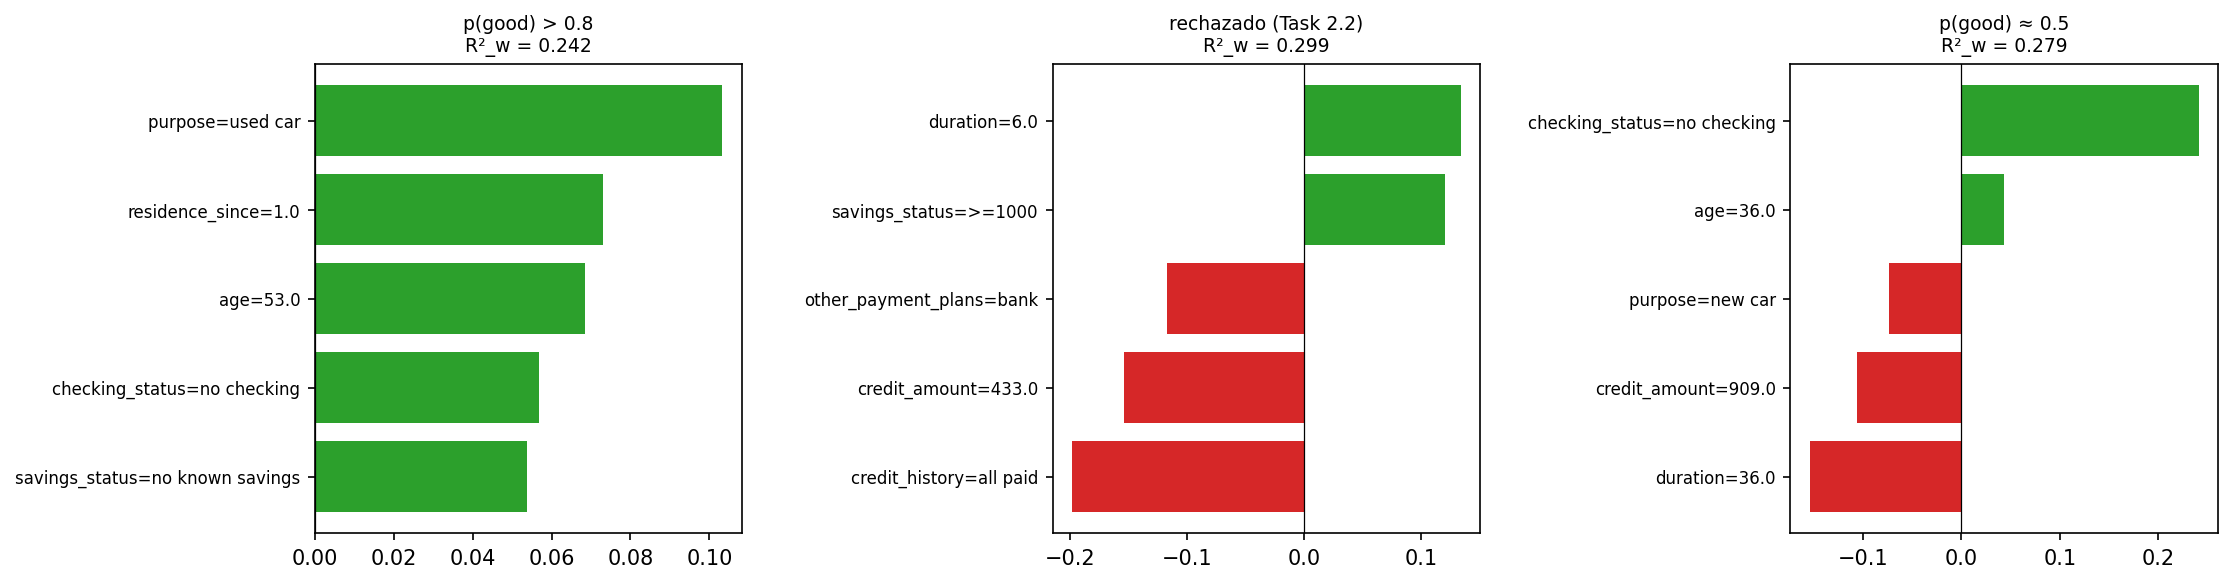

,cliente,variable,valor,coef,R²_w
0,p(good) > 0.8,purpose,used car,0.103222,0.2424
1,p(good) > 0.8,residence_since,1.0,0.073125,0.2424
2,p(good) > 0.8,age,53.0,0.068445,0.2424
3,p(good) > 0.8,checking_status,no checking,0.056801,0.2424
4,p(good) > 0.8,savings_status,no known savings,0.053743,0.2424
5,rechazado (Task 2.2),credit_history,all paid,-0.198442,0.2993
6,rechazado (Task 2.2),credit_amount,433.0,-0.154490,0.2993
7,rechazado (Task 2.2),duration,6.0,0.133582,0.2993
8,rechazado (Task 2.2),savings_status,>=1000,0.120211,0.2993
9,rechazado (Task 2.2),other_payment_plans,bank,-0.117581,0.2993


In [17]:
# LIME tabular desde cero (sin la librería lime) sobre el modelo gb del Task 2.1.
N, K, LAM, SIGMA_REL = 5000, 5, 1.0, 0.75
d = len(COLS)                                   # d' = 20
sigma2 = (SIGMA_REL * np.sqrt(d)) ** 2          # sigma^2 = 0.75^2 * 20 = 11.25
Xtr_vals = X_tr.values

def muestrear_z(x, rng):
    """z' binaria (N x d) y la entrada real z: presente = valor de x, ausente = muestra de X_tr."""
    Zp = (rng.random((N, d)) < 0.5).astype(float)                 # 1 con probabilidad 0.5
    idx = rng.integers(0, Xtr_vals.shape[0], size=(N, d))         # fila al azar por celda
    Zreal = np.where(Zp == 1, x, Xtr_vals[idx, np.arange(d)])     # ausente -> valor al azar de la columna
    return Zp, Zreal

def ridge_ponderada(Zp, y, pesos, lam):
    """Forma cerrada w = (A'ΠA + λR)^-1 A'Πy, con A = [1, Zp]. El intercepto no se penaliza (R[0,0]=0)."""
    A = np.column_stack([np.ones(len(Zp)), Zp])                   # columna de unos para el intercepto
    AW = A * pesos[:, None]                                       # A'Π sin formar Π densa (NxN)
    R = np.eye(A.shape[1]); R[0, 0] = 0.0
    w = np.linalg.solve(A.T @ AW + lam * R, AW.T @ y)
    return w, A

def lime_tabular(i):
    rng = np.random.default_rng(SEED)
    x = X_te.iloc[i].values
    Zp, Zreal = muestrear_z(x, rng)
    y = gb.predict_proba(Zreal)[:, 1]                             # salida a explicar: prob de good
    pesos = np.exp(-(d - Zp.sum(1)) / sigma2)                     # D^2 = número de variables ausentes
    w20, _ = ridge_ponderada(Zp, y, pesos, LAM)                  # 1) ajuste sobre las 20 variables
    top = np.argsort(-np.abs(w20[1:]))[:K]                       # K variables de mayor |w|
    wk, Ak = ridge_ponderada(Zp[:, top], y, pesos, LAM)         # 2) reajuste solo con las K
    g = Ak @ wk
    ybar = (pesos * y).sum() / pesos.sum()                       # media ponderada
    R2w = 1 - (pesos * (y - g) ** 2).sum() / (pesos * (y - ybar) ** 2).sum()
    return top, wk, R2w

i_mid = int(np.argmin(np.abs(p_te - 0.5)))                       # cliente con p(good) en [0.45, 0.55]
CLIENTES = [("p(good) > 0.8", i_ok), ("rechazado (Task 2.2)", i_rech), ("p(good) ≈ 0.5", i_mid)]

fig, ax = plt.subplots(1, 3, figsize=(15, 4)); LIME = {}
for a, (nombre, i) in zip(ax, CLIENTES):
    top, wk, R2w = lime_tabular(i); LIME[nombre] = (i, top, wk, R2w)
    coef = wk[1:]
    vals = [decodificar(COLS[j], X_te.iloc[i][COLS[j]]) for j in top]
    print(f"{nombre}: idx {X_te.index[i]}, p(good) = {p_te[i]:.4f}, R²_w = {R2w:.4f}")
    for j, c, v in zip(top, coef, vals):
        print(f"    {COLS[j]:24s} = {str(v):18s} coef = {c:+.4f}")
    orden = np.argsort(coef); etiquetas = [f"{COLS[j]}={v}" for j, v in zip(top, vals)]
    a.barh(range(K), coef[orden], color=["tab:red" if c < 0 else "tab:green" for c in coef[orden]])
    a.set_yticks(range(K)); a.set_yticklabels([etiquetas[t] for t in orden], fontsize=8)
    a.axvline(0, color="k", lw=0.6); a.set_title(f"{nombre}\nR²_w = {R2w:.3f}", fontsize=9)
plt.tight_layout(); plt.savefig("figs/t3_lime.png", dpi=150, bbox_inches="tight"); plt.show()

T31 = pd.DataFrame(
    [(nombre, COLS[j], decodificar(COLS[j], X_te.iloc[i][COLS[j]]), float(wk[1 + r]), round(float(R2w), 4))
     for nombre, (i, top, wk, R2w) in LIME.items() for r, j in enumerate(top)],
    columns=["cliente", "variable", "valor", "coef", "R²_w"])
T31

### Task 3.2 – Estabilidad de LIME

Estabilidad en el cliente rechazado: para cada combinación de $N\in\{500,2000,5000\}$ y $\sigma_{rel}\in\{0.5,0.75,1.5\}$ se ejecuta LIME 20 veces con **semillas distintas** (0 a 19). Se reporta el índice de Jaccard promedio $J(A,B)=|A\cap B|/|A\cup B|$ entre los conjuntos de las $K=5$ variables principales de todos los pares de corridas (190 pares), y el tamaño efectivo de muestra promedio $N_{ef}=(\sum_n\pi_n)^2/\sum_n\pi_n^2$.

In [18]:
from IPython.display import display

def lime_run(i, N, sigma_rel, K, seed):
    """LIME configurable. Devuelve top-K (set), |w| de las 20 variables, R²_w y N_ef."""
    rng = np.random.default_rng(seed)
    x = X_te.iloc[i].values
    Zp = (rng.random((N, d)) < 0.5).astype(float)
    idx = rng.integers(0, Xtr_vals.shape[0], size=(N, d))
    Zreal = np.where(Zp == 1, x, Xtr_vals[idx, np.arange(d)])
    y = gb.predict_proba(Zreal)[:, 1]
    pesos = np.exp(-(d - Zp.sum(1)) / (sigma_rel * np.sqrt(d)) ** 2)   # D^2 = nro. ausentes
    w20, _ = ridge_ponderada(Zp, y, pesos, LAM)                       # ajuste sobre las 20 variables
    top = np.argsort(-np.abs(w20[1:]))[:K]                            # K de mayor |w|
    wk, Ak = ridge_ponderada(Zp[:, top], y, pesos, LAM); g = Ak @ wk  # reajuste con las K
    ybar = (pesos * y).sum() / pesos.sum()
    R2w = 1 - (pesos * (y - g) ** 2).sum() / (pesos * (y - ybar) ** 2).sum()
    Nef = pesos.sum() ** 2 / (pesos ** 2).sum()                       # tamaño efectivo de muestra
    return dict(top=set(top.tolist()), w_abs=np.abs(w20[1:]), R2w=R2w, Nef=Nef)

Ns, SRELS, REP, Kstab = [500, 2000, 5000], [0.5, 0.75, 1.5], 20, 5   # 20 semillas distintas: 0..19
jac = pd.DataFrame(index=Ns, columns=SRELS, dtype=float)
nef = pd.DataFrame(index=Ns, columns=SRELS, dtype=float)
for Nv in Ns:
    for sr in SRELS:
        tops, nefs = [], []
        for s in range(REP):
            r = lime_run(i_rech, Nv, sr, Kstab, s); tops.append(r["top"]); nefs.append(r["Nef"])
        jac.loc[Nv, sr] = np.mean([len(a & b) / len(a | b) for a, b in itertools.combinations(tops, 2)])
        nef.loc[Nv, sr] = np.mean(nefs)
jac.index.name = nef.index.name = "N"; jac.columns.name = nef.columns.name = "σ_rel"
print("Jaccard promedio de las K=5 variables principales (190 pares por combinación):")
display(jac.round(4))
print("Tamaño efectivo de muestra promedio N_ef:")
display(nef.round(1))

Jaccard promedio de las K=5 variables principales (190 pares por combinación):


σ_rel,0.50,0.75,1.50
N,,,
500,0.8549,0.8291,0.8115
2000,0.9667,0.9667,0.9667
5000,1.0000,1.0000,1.0000


Tamaño efectivo de muestra promedio N_ef:


σ_rel,0.50,0.75,1.50
N,,,
500,407.9,480.3,498.7
2000,1637.9,1922.0,1995.0
5000,4098.9,4805.9,4987.6


### Task 3.3 – Comparación LIME vs SHAP

**(a)** Correlación de Spearman entre $|w|$ de LIME (ajuste sobre las 20 variables, configuración de Task 3.1: $N=5000$, $\sigma_{rel}=0.75$, semilla 42) y $|\phi|$ de SHAP (Task 2.2), y coincidencia entre las 3 variables principales de cada método.
**(b)** Para el cliente rechazado, $R^2_w$ al ajustar LIME con $K\in\{3,5,10,20\}$.

In [19]:
# (a) Spearman entre |w| de LIME (20 vars) y |phi| de SHAP (Task 2.2) + coincidencia top-3.
filas = []
for nombre, i in CLIENTES:
    w_abs = lime_run(i, 5000, 0.75, 5, SEED)["w_abs"]       # |w| de las 20 variables (config Task 3.1)
    phi_abs = np.abs(phi[i])                                # |phi| de SHAP del Task 2.2
    rho = float(spearmanr(w_abs, phi_abs).statistic)
    t3_lime = [COLS[j] for j in np.argsort(-w_abs)[:3]]
    t3_shap = [COLS[j] for j in np.argsort(-phi_abs)[:3]]
    comunes = sorted(set(t3_lime) & set(t3_shap))
    filas.append({"cliente": nombre, "ρ Spearman": round(rho, 4), "top-3 LIME": t3_lime,
                  "top-3 SHAP": t3_shap, "coinciden": len(comunes)})
    print(f"{nombre}: ρ = {rho:.4f} | top-3 comunes ({len(comunes)}): {comunes}")
T33a = pd.DataFrame(filas)
T33a

p(good) > 0.8: ρ = 0.6917 | top-3 comunes (3): ['age', 'purpose', 'residence_since']
rechazado (Task 2.2): ρ = 0.9759 | top-3 comunes (2): ['credit_amount', 'credit_history']
p(good) ≈ 0.5: ρ = 0.9308 | top-3 comunes (3): ['checking_status', 'credit_amount', 'duration']


,cliente,ρ Spearman,top-3 LIME,top-3 SHAP,coinciden
0,p(good) > 0.8,0.6917,"[purpose, residence_since, age]","[purpose, age, residence_since]",3
1,rechazado (Task 2.2),0.9759,"[credit_history, credit_amount, duration]","[credit_history, savings_status, credit_amount]",2
2,p(good) ≈ 0.5,0.9308,"[checking_status, duration, credit_amount]","[checking_status, duration, credit_amount]",3


In [20]:
# (b) Fidelidad local R²_w del cliente rechazado al variar K (K=20 = ajuste completo de 20 variables).
T33b = pd.DataFrame({"K": [3, 5, 10, 20]})
T33b["R²_w"] = [round(float(lime_run(i_rech, 5000, 0.75, K, SEED)["R2w"]), 4) for K in [3, 5, 10, 20]]
print("Cliente rechazado – fidelidad local R²_w según K:")
T33b

Cliente rechazado – fidelidad local R²_w según K:


,K,R²_w
0,3,0.2228
1,5,0.2993
2,10,0.3628
3,20,0.3717


### Task 3.4 - Explicaciones contrafactuales

Busqueda por muestreo para el cliente rechazado: 20000 candidatos, maximo 3 variables accionables cambiadas, umbral theta = 0.5. Accionables: duration, credit_amount, installment_commitment, checking_status, savings_status. Inmutables: age, personal_status, foreign_worker. El analisis y la lectura de resultados estan en Task3_docs.md.

In [21]:
# Contrafactuales por muestreo para el cliente rechazado.
INMUT = ["age", "personal_status", "foreign_worker"]
ACCION = ["duration", "credit_amount", "installment_commitment", "checking_status", "savings_status"]
acc_pos = [COLS.index(c) for c in ACCION]
num_pos = [COLS.index(c) for c in NUM]; cat_pos = [COLS.index(c) for c in CAT]
MAD = {}
for c in NUM:
    col = X_tr[c].values; m = np.median(np.abs(col - np.median(col)))
    MAD[c] = m if m > 0 else np.mean(np.abs(col - np.mean(col)))
mad_arr = np.array([MAD[COLS[p]] for p in num_pos])
x0 = X_te.iloc[i_rech].values

def generar_cf(n_cand, max_camb, seed):
    rng = np.random.default_rng(seed)
    ks = rng.integers(1, max_camb + 1, size=n_cand)
    mask = rng.random((n_cand, len(ACCION))).argsort(1).argsort(1) < ks[:, None]
    srow = rng.integers(0, Xtr_vals.shape[0], size=(n_cand, len(ACCION)))
    cand = np.tile(x0, (n_cand, 1)).astype(float)
    for a, p in enumerate(acc_pos):
        cand[:, p] = np.where(mask[:, a], Xtr_vals[srow[:, a], p], x0[p])
    prob = gb.predict_proba(pd.DataFrame(cand, columns=COLS))[:, 1]
    dif = cand != x0
    dist = (np.abs(cand[:, num_pos] - x0[num_pos]) / mad_arr).sum(1) + dif[:, cat_pos].sum(1)
    return cand, prob, dif, dist

THETA, max_camb = 0.5, 3
cand, prob, dif, dist = generar_cf(20000, max_camb, SEED)
if (prob >= THETA).sum() == 0:
    max_camb = 5; cand, prob, dif, dist = generar_cf(20000, max_camb, SEED)
valid = prob >= THETA; camb = dif[:, acc_pos].sum(1)
print(f"max_camb={max_camb}  validez={valid.mean():.4f} ({valid.sum()}/20000)  "
      f"proximidad={dist[valid].mean():.3f}  dispersion={camb[valid].mean():.3f}")

orden = np.argsort(dist); orden = orden[valid[orden]]
elegidos, sets = [], []
for k in orden:
    s = frozenset(COLS[p] for p in np.where(dif[k])[0])
    if s not in sets: elegidos.append(k); sets.append(s)
    if len(elegidos) == 3: break
T34 = pd.DataFrame([{"CF": r, "variable": COLS[p], "original": decodificar(COLS[p], x0[p]),
                     "nuevo": decodificar(COLS[p], cand[k, p]), "distancia": round(float(dist[k]), 3),
                     "p_good": round(float(prob[k]), 4)}
                    for r, k in enumerate(elegidos, 1) for p in np.where(dif[k])[0]])
T34

max_camb=3  validez=0.0041 (82/20000)  proximidad=3.264  dispersion=2.561


,CF,variable,original,nuevo,distancia,p_good
0,1,checking_status,0<=X<200,no checking,1.005,0.6535
1,1,credit_amount,433.0,428.0,1.005,0.6535
2,2,credit_amount,433.0,426.0,2.007,0.5836
3,2,installment_commitment,4.0,2.0,2.007,0.5836
4,3,checking_status,0<=X<200,>=200,2.045,0.6207
5,3,credit_amount,433.0,385.0,2.045,0.6207
6,3,savings_status,>=1000,no known savings,2.045,0.6207


### Task 3.5 - Analisis

(a) Nef vs Jaccard y numero de muestras para Jaccard 0.9. (b) Variable de mayor discrepancia LIME vs SHAP. (c) Eleccion de K. (d) Contrafactuales vs mayor |phi|. Las respuestas estan en Task3_docs.md.

Nef/N=0.961  N_est(J=0.9)=787  J(787)=0.8013


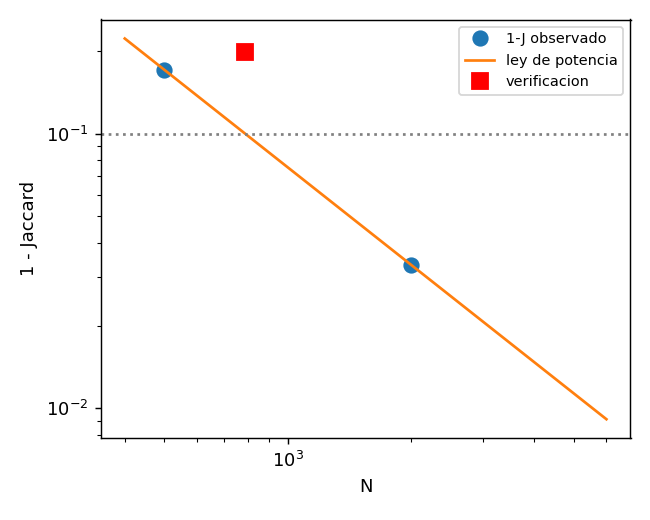

In [22]:
# (a) N para Jaccard=0.9 (sigma_rel=0.75): ley de potencia sobre 1-J + verificacion.
J500, J2000 = jac.loc[500, 0.75], jac.loc[2000, 0.75]
b_, a_ = np.polyfit(np.log([500, 2000]), np.log([1 - J500, 1 - J2000]), 1)
N_est = int(np.exp((np.log(0.1) - a_) / b_))
tops = [lime_run(i_rech, N_est, 0.75, 5, s)["top"] for s in range(20)]
J_ver = np.mean([len(u & v) / len(u | v) for u, v in itertools.combinations(tops, 2)])
print(f"Nef/N={nef.loc[5000, 0.75] / 5000:.3f}  N_est(J=0.9)={N_est}  J({N_est})={J_ver:.4f}")
NN = [500, 2000]
plt.figure(figsize=(5, 4))
plt.loglog(NN, [1 - jac.loc[n, 0.75] for n in NN], "o", ms=8, label="1-J observado")
grid = np.array([400, 6000]); plt.loglog(grid, np.exp(a_) * grid ** b_, "-", label="ley de potencia")
plt.loglog([N_est], [1 - J_ver], "rs", ms=9, label="verificacion")
plt.axhline(0.1, color="gray", ls=":")
plt.xlabel("N"); plt.ylabel("1 - Jaccard"); plt.legend(fontsize=8); plt.tight_layout()
plt.savefig("figs/t35a.png", dpi=130); plt.show()

max discrepancia: rechazado (Task 2.2), savings_status (|delta|=0.031)
norm|phi|=0.132  norm|w| por sigma_rel=[0.076, 0.099, 0.101, 0.102]


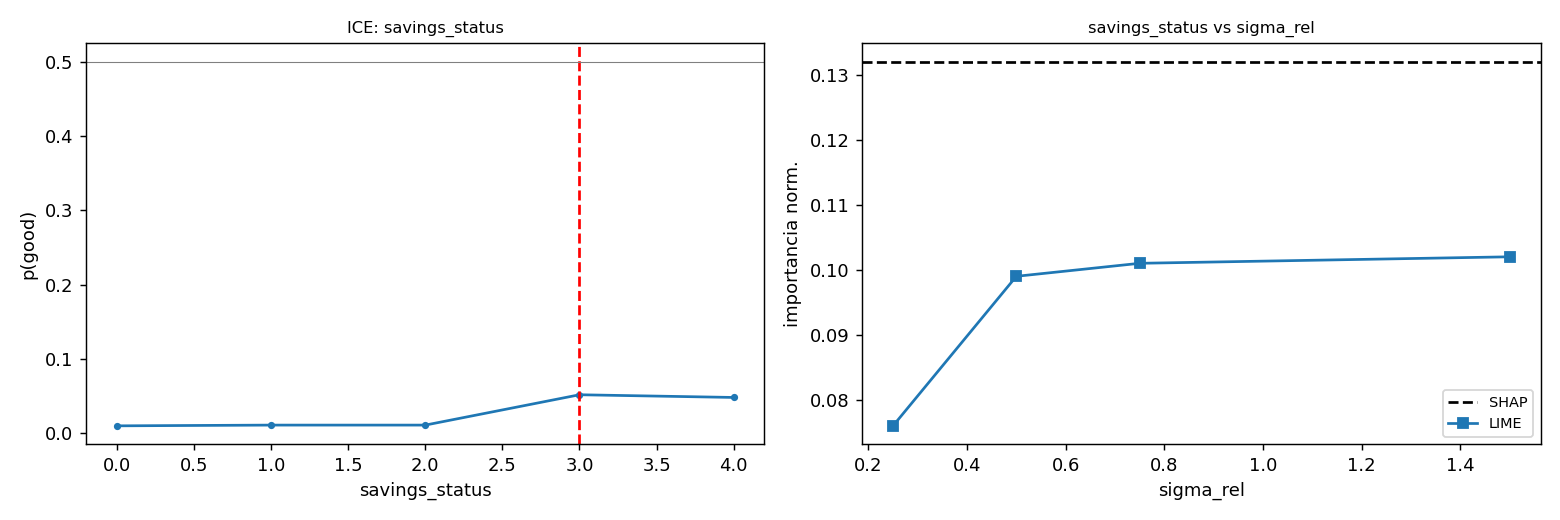

In [23]:
# (b) Cliente y variable de maxima discrepancia LIME vs SHAP; prueba con ICE y sigma_rel.
best = (-1.0, None, None)
for nombre, i in CLIENTES:
    w = lime_run(i, 5000, 0.75, 5, SEED)["w_abs"]; ph = np.abs(phi[i])
    disc = np.abs(w / w.sum() - ph / ph.sum()); j = int(np.argmax(disc))
    if disc[j] > best[0]: best = (disc[j], i, j)
ci, cj = best[1], best[2]; cnom = [n for n, i in CLIENTES if i == ci][0]
print(f"max discrepancia: {cnom}, {COLS[cj]} (|delta|={best[0]:.3f})")
vals = np.unique(Xtr_vals[:, cj])
Xs = np.tile(X_te.iloc[ci].values, (len(vals), 1)).astype(float); Xs[:, cj] = vals
ps = gb.predict_proba(pd.DataFrame(Xs, columns=COLS))[:, 1]
srs = [0.25, 0.5, 0.75, 1.5]; nph = np.abs(phi[ci])[cj] / np.abs(phi[ci]).sum()
nw = []
for sr in srs:
    w = lime_run(ci, 5000, sr, 5, SEED)["w_abs"]; nw.append(float(round(w[cj] / w.sum(), 3)))
print(f"norm|phi|={nph:.3f}  norm|w| por sigma_rel={nw}")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(vals, ps, marker="o", ms=3); ax[0].axvline(X_te.iloc[ci].values[cj], color="r", ls="--")
ax[0].axhline(0.5, color="gray", lw=0.6); ax[0].set_xlabel(COLS[cj]); ax[0].set_ylabel("p(good)")
ax[0].set_title("ICE: " + COLS[cj], fontsize=9)
ax[1].axhline(nph, color="k", ls="--", label="SHAP"); ax[1].plot(srs, nw, marker="s", label="LIME")
ax[1].set_xlabel("sigma_rel"); ax[1].set_ylabel("importancia norm."); ax[1].legend(fontsize=8)
ax[1].set_title(COLS[cj] + " vs sigma_rel", fontsize=9)
plt.tight_layout(); plt.savefig("figs/t35b.png", dpi=130); plt.show()

In [24]:
# (c) Ganancia marginal de fidelidad al aumentar K (tabla del Task 3.3b).
T35c = pd.DataFrame({"K": T33b["K"], "R2_w": T33b["R2_w"]})
T35c["gain"] = T35c["R2_w"].diff().round(4)
T35c

,K,R2_w,gain
0,3,0.2228,NaN
1,5,0.2993,0.0765
2,10,0.3628,0.0635
3,20,0.3717,0.0089


In [25]:
# (d) SHAP (atribucion) vs contrafactual (recurso) para el rechazado.
ph = np.abs(phi[i_rech]); top3 = np.argsort(-ph)[:3]
estado = lambda c: "accionable" if c in ACCION else ("inmutable" if c in INMUT else "no accionable")
for j in top3:
    print(f"{COLS[j]:16s} |phi|={ph[j]:.3f}  {estado(COLS[j])}")
cf_vars = sorted(set(T34["variable"]))
print("cambian en contrafactuales:", cf_vars)
print("alto |phi| ausente:", [COLS[j] for j in top3 if COLS[j] not in cf_vars])

credit_history   |phi|=1.258  no accionable
savings_status   |phi|=1.027  accionable
credit_amount    |phi|=0.993  accionable
cambian en contrafactuales: ['checking_status', 'credit_amount', 'installment_commitment', 'savings_status']
alto |phi| ausente: ['credit_history']
